# MOSAIC-ML — Model training and comparison (3 models)

Trains and compares the three MOSAIC-ML classifiers on the MH-100K Android
malware dataset: **Logistic Regression, Linear SVM, Random Forest (30 trees)**.
They are alternatives compared fairly, not an ensemble.

**Every number below is computed in this runtime.** Nothing is pre-filled. The
last section compares this run with the numbers shipped in the project.

### Protocol
1. Label: malware when `vt_detection >= 4` (MH-100K's `classes` array).
2. **Deduplicate**: apps with an identical set of active features are kept once,
   so no app can sit in both train and test.
3. **Stratified 70 / 15 / 15** split, seed 42.
4. **9 configurations** scored on **validation only**.
5. Selection on **balanced accuracy**, decided in advance. Plain accuracy is
   misleading here: predicting "benign" for everything already scores ~0.87.
6. The winner is refit on train + validation and evaluated **once** on test.
7. A **control** model that sees only the *number* of active features shows
   how much of the score is a dataset shortcut.

## 0. (Optional) exact-version reproduction

The shipped models were trained with scikit-learn 1.6.1, NumPy 1.26.4 and
SciPy 1.15.3. Colab's default versions are newer. Results under other versions
are usually identical or differ only in the last decimal places.

For an exact match, uncomment and run the cell below, then use
**Runtime → Restart session** and continue from section 1.

In [1]:
# !pip -q install "numpy==1.26.4" "scipy==1.15.3" "scikit-learn==1.6.1" "joblib==1.5.3"

## 1. Setup

In [2]:
import sys, os, time, json, hashlib, platform
import numpy as np, scipy, scipy.sparse as sp, sklearn
import matplotlib.pyplot as plt
import pandas as pd

print("python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("scipy       :", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
SEED = 42
plt.rcParams.update({"font.size": 9, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})
COL = {"Logistic Regression": "#2E6FBA", "Linear SVM": "#E07B00",
       "Random Forest": "#2A9D5C", "Control": "#B0413E"}

python      : 3.10.20
numpy       : 1.26.4
scipy       : 1.15.3
scikit-learn: 1.6.1


## 2. Load MH-100K

Put `mh100.npz` (~86 MB) in Google Drive at `MyDrive/MOSAIC-ML/mh100.npz`,
or change the path. Outside Colab, the `MH100_NPZ` environment variable or
`data/mh100k/mh100.npz` is used.

In [3]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    NPZ_PATH = '/content/drive/MyDrive/MOSAIC-ML/mh100.npz'
except ImportError:
    NPZ_PATH = os.environ.get('MH100_NPZ', 'data/mh100k/mh100.npz')
assert os.path.exists(NPZ_PATH), f"Not found: {NPZ_PATH}"
print("Using:", NPZ_PATH, f"({os.path.getsize(NPZ_PATH)/1e6:.1f} MB)")

Using: data/mh100k/mh100.npz (85.7 MB)


**Important.** MH-100K stores its matrix in column-major (Fortran) order.
`np.load` handles that correctly; reading the raw file in row-chunks does not,
and silently scrambles every row. That exact bug once made every model score
at chance level. The check after loading catches it.

In [4]:
t0 = time.time()
z = np.load(NPZ_PATH, allow_pickle=True)
y_all = np.asarray(z['classes']).astype(int)
vocab = np.asarray(z['column_names'])
dense = z['data']
print("dense:", dense.shape, dense.dtype, "fortran_order:", dense.flags['F_CONTIGUOUS'])

blocks = [sp.csr_matrix(dense[s:s+5000]) for s in range(0, dense.shape[0], 5000)]
X_all = sp.vstack(blocks, format='csr'); del blocks, dense
import gc; gc.collect()
print(f"CSR {X_all.shape}  nnz={X_all.nnz:,}  density={X_all.nnz/np.prod(X_all.shape):.4%}"
      f"  ({time.time()-t0:.0f}s)")

# Integrity check: correctly loaded rows vary a lot in size (tens to thousands).
# A scrambled matrix has nearly identical row sizes (~15,600 each).
row_nnz = np.diff(X_all.indptr)
print("first rows' active features:", row_nnz[:6].tolist())
assert X_all.nnz == 185_917_518, "unexpected non-zero count"
assert row_nnz.std() > 500, "row sizes are suspiciously uniform - matrix is scrambled"
print("integrity check passed")

dense: (101934, 24833) int8 fortran_order: True


CSR (101934, 24833)  nnz=185,917,518  density=7.3447%  (25s)
first rows' active features: [1288, 2291, 2700, 41, 2345, 2324]
integrity check passed


In [5]:
from collections import Counter
blocks_count = Counter(str(v).split('::')[0] for v in vocab)
print("feature blocks:", dict(blocks_count), "| total", len(vocab))
n0, n1 = int((y_all == 0).sum()), int((y_all == 1).sum())
print(f"benign {n0:,}  malware {n1:,}  ({n1/len(y_all):.2%} malware, ratio {n0/n1:.2f}:1)")

feature blocks: {'Permission': 166, 'Intent': 250, 'APICall': 24417} | total 24833
benign 92,134  malware 9,800  (9.61% malware, ratio 9.40:1)


## 3. Deduplicate

In [6]:
seen, keep, conflicts = {}, [], 0
for i in range(X_all.shape[0]):
    lo, hi = X_all.indptr[i], X_all.indptr[i+1]
    d = hashlib.blake2b(X_all.indices[lo:hi].astype(np.int32).tobytes(), digest_size=16).digest()
    if d in seen:
        conflicts += int(y_all[seen[d]] != y_all[i])
    else:
        seen[d] = i; keep.append(i)
keep = np.array(keep)
X, y = X_all[keep], y_all[keep]
print(f"{len(y_all):,} rows -> {len(keep):,} unique ({len(y_all)-len(keep):,} duplicates removed)")
print(f"duplicates with a different label: {conflicts:,} (first occurrence kept)")
print(f"malware after deduplication: {y.mean():.2%}  ->  all-benign accuracy = {1-y.mean():.4f}")

101,934 rows -> 58,576 unique (43,358 duplicates removed)
duplicates with a different label: 1,024 (first occurrence kept)
malware after deduplication: 13.10%  ->  all-benign accuracy = 0.8690


## 4. Split 70 / 15 / 15 (test is not touched until section 7)

In [7]:
from sklearn.model_selection import train_test_split
idx = np.arange(X.shape[0])
i_tr, i_tmp = train_test_split(idx, test_size=0.30, random_state=SEED, stratify=y)
i_va, i_te  = train_test_split(i_tmp, test_size=0.50, random_state=SEED, stratify=y[i_tmp])
X_tr, y_tr = X[i_tr], y[i_tr]
X_va, y_va = X[i_va], y[i_va]
X_te, y_te = X[i_te], y[i_te]
for nm, yy in [('train', y_tr), ('validation', y_va), ('test', y_te)]:
    print(f"{nm:11s} {len(yy):6,}   malware {int(yy.sum()):5,} ({yy.mean():.2%})")

train       41,003   malware 5,370 (13.10%)
validation   8,786   malware 1,150 (13.09%)
test         8,787   malware 1,151 (13.10%)


## 5. The 9 configurations

`class_weight="balanced"` makes the training loss weigh each malware app more
heavily, in proportion to how rare malware is, instead of letting the majority
class dominate. It is the main lever for an imbalanced problem.

Random Forest is fixed at 30 trees by the project specification.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

GRID = [
    ("LR  C=1    (baseline)", lambda: LogisticRegression(max_iter=2000, random_state=SEED), "Logistic Regression"),
    ("LR  C=1    balanced",   lambda: LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED), "Logistic Regression"),
    ("LR  C=0.1  balanced",   lambda: LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced", random_state=SEED), "Logistic Regression"),
    ("LR  C=10   balanced",   lambda: LogisticRegression(C=10, max_iter=3000, class_weight="balanced", random_state=SEED), "Logistic Regression"),
    ("SVM C=1    (baseline)", lambda: LinearSVC(random_state=SEED, max_iter=3000), "Linear SVM"),
    ("SVM C=1    balanced",   lambda: LinearSVC(class_weight="balanced", random_state=SEED, max_iter=3000), "Linear SVM"),
    ("SVM C=0.1  balanced",   lambda: LinearSVC(C=0.1, class_weight="balanced", random_state=SEED, max_iter=3000), "Linear SVM"),
    ("RF  30     (baseline)", lambda: RandomForestClassifier(n_estimators=30, max_features="sqrt", random_state=SEED, n_jobs=-1), "Random Forest"),
    ("RF  30     balanced",   lambda: RandomForestClassifier(n_estimators=30, max_features="sqrt", class_weight="balanced", random_state=SEED, n_jobs=-1), "Random Forest"),
]
MAKE = {name: make for name, make, _ in GRID}

## 6. Train every configuration, score on validation

In [9]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, roc_auc_score, average_precision_score)

def score_of(m, Xs):
    return m.predict_proba(Xs)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xs)

def evaluate(name, family, model, Xa, ya, Xb, yb):
    t0 = time.time(); model.fit(Xa, ya); fit_s = time.time() - t0
    pred = model.predict(Xb); sc = score_of(model, Xb)
    tn, fp, fn, tp = confusion_matrix(yb, pred, labels=[0, 1]).ravel()
    return dict(config=name, family=family,
        accuracy=accuracy_score(yb, pred), balanced_accuracy=balanced_accuracy_score(yb, pred),
        malware_precision=precision_score(yb, pred, zero_division=0),
        malware_recall=recall_score(yb, pred, zero_division=0),
        malware_f1=f1_score(yb, pred, zero_division=0),
        false_positive_rate=fp/(fp+tn), roc_auc=roc_auc_score(yb, sc),
        pr_auc=average_precision_score(yb, sc), TN=tn, FP=fp, FN=fn, TP=tp, fit_seconds=fit_s), model

rows, fitted, val_scores = [], {}, {}
for name, make, family in GRID:
    r, m = evaluate(name, family, make(), X_tr, y_tr, X_va, y_va)
    rows.append(r); fitted[name] = m; val_scores[name] = score_of(m, X_va)
    print(f"{name:24s} bal={r['balanced_accuracy']:.4f}  recall={r['malware_recall']:.4f}  "
          f"fpr={r['false_positive_rate']:.4f}  ({r['fit_seconds']:.0f}s)")

# Control: one input, the count of active features.
cnt = lambda M: np.diff(M.indptr).astype(float).reshape(-1, 1)
r, _ = evaluate("CONTROL active-count", "Control", DecisionTreeClassifier(max_depth=3, random_state=SEED),
                cnt(X_tr), y_tr, cnt(X_va), y_va)
rows.append(r)
print(f"{'CONTROL active-count':24s} bal={r['balanced_accuracy']:.4f}  recall={r['malware_recall']:.4f}")

LR  C=1    (baseline)    bal=0.9598  recall=0.9417  fpr=0.0221  (50s)


LR  C=1    balanced      bal=0.9631  recall=0.9565  fpr=0.0303  (47s)


LR  C=0.1  balanced      bal=0.9630  recall=0.9565  fpr=0.0305  (37s)


LR  C=10   balanced      bal=0.9630  recall=0.9557  fpr=0.0297  (60s)


SVM C=1    (baseline)    bal=0.9573  recall=0.9435  fpr=0.0289  (94s)


SVM C=1    balanced      bal=0.9594  recall=0.9530  fpr=0.0343  (372s)


SVM C=0.1  balanced      bal=0.9612  recall=0.9548  fpr=0.0323  (90s)


RF  30     (baseline)    bal=0.9493  recall=0.9174  fpr=0.0187  (51s)


RF  30     balanced      bal=0.9504  recall=0.9191  fpr=0.0183  (54s)
CONTROL active-count     bal=0.8794  recall=0.7904


In [10]:
val = pd.DataFrame(rows).set_index("config")
cols = ["family", "accuracy", "balanced_accuracy", "malware_recall", "malware_precision",
        "malware_f1", "false_positive_rate", "roc_auc", "pr_auc"]
display(val[cols].round(4))

real = val[val.family != "Control"]
best_per_family = real.groupby("family")["balanced_accuracy"].idxmax()
SELECTED = real["balanced_accuracy"].idxmax()
print("Best of each model:")
for fam, cfg in best_per_family.items():
    print(f"  {fam:20s} {cfg:24s} balanced accuracy {val.loc[cfg,'balanced_accuracy']:.4f}")
print(f"\nSELECTED (validation balanced accuracy): {SELECTED}")
ctrl = val.loc["CONTROL active-count"]
print(f"Gain over the count-only control in malware recall: "
      f"{val.loc[SELECTED,'malware_recall'] - ctrl['malware_recall']:+.4f}")

,family,accuracy,balanced_accuracy,malware_recall,malware_precision,malware_f1,false_positive_rate,roc_auc,pr_auc
config,,,,,,,,,
LR C=1 (baseline),Logistic Regression,0.9731,0.9598,0.9417,0.8650,0.9017,0.0221,0.9796,0.9022
LR C=1 balanced,Logistic Regression,0.9680,0.9631,0.9565,0.8264,0.8867,0.0303,0.9793,0.9050
LR C=0.1 balanced,Logistic Regression,0.9678,0.9630,0.9565,0.8252,0.8860,0.0305,0.9831,0.9215
LR C=10 balanced,Logistic Regression,0.9684,0.9630,0.9557,0.8288,0.8877,0.0297,0.9762,0.8848
SVM C=1 (baseline),Linear SVM,0.9674,0.9573,0.9435,0.8308,0.8836,0.0289,0.9756,0.8598
SVM C=1 balanced,Linear SVM,0.9640,0.9594,0.9530,0.8071,0.8740,0.0343,0.9747,0.8381
SVM C=0.1 balanced,Linear SVM,0.9660,0.9612,0.9548,0.8164,0.8802,0.0323,0.9767,0.8742
RF 30 (baseline),Random Forest,0.9729,0.9493,0.9174,0.8806,0.8986,0.0187,0.9822,0.9098
RF 30 balanced,Random Forest,0.9735,0.9504,0.9191,0.8830,0.9007,0.0183,0.9823,0.9052


Best of each model:
  Linear SVM           SVM C=0.1  balanced      balanced accuracy 0.9612
  Logistic Regression  LR  C=1    balanced      balanced accuracy 0.9631
  Random Forest        RF  30     balanced      balanced accuracy 0.9504

SELECTED (validation balanced accuracy): LR  C=1    balanced
Gain over the count-only control in malware recall: +0.1661


## 7. Refit the selected configuration on train + validation, evaluate ONCE on test

In [11]:
X_fit = sp.vstack([X_tr, X_va], format="csr"); y_fit = np.concatenate([y_tr, y_va])
test, final_model = evaluate(SELECTED, val.loc[SELECTED, "family"], MAKE[SELECTED](),
                             X_fit, y_fit, X_te, y_te)
for k in ["accuracy", "balanced_accuracy", "malware_precision", "malware_recall",
          "malware_f1", "false_positive_rate", "roc_auc", "pr_auc"]:
    print(f"  {k:20s} {test[k]:.4f}")
print(f"  confusion: TN {test['TN']:,}  FP {test['FP']:,}  FN {test['FN']:,}  TP {test['TP']:,}")

  accuracy             0.9675
  balanced_accuracy    0.9569
  malware_precision    0.8314
  malware_recall       0.9427
  malware_f1           0.8836
  false_positive_rate  0.0288
  roc_auc              0.9785
  pr_auc               0.8978
  confusion: TN 7,416  FP 220  FN 66  TP 1,085


## 8. Graphs

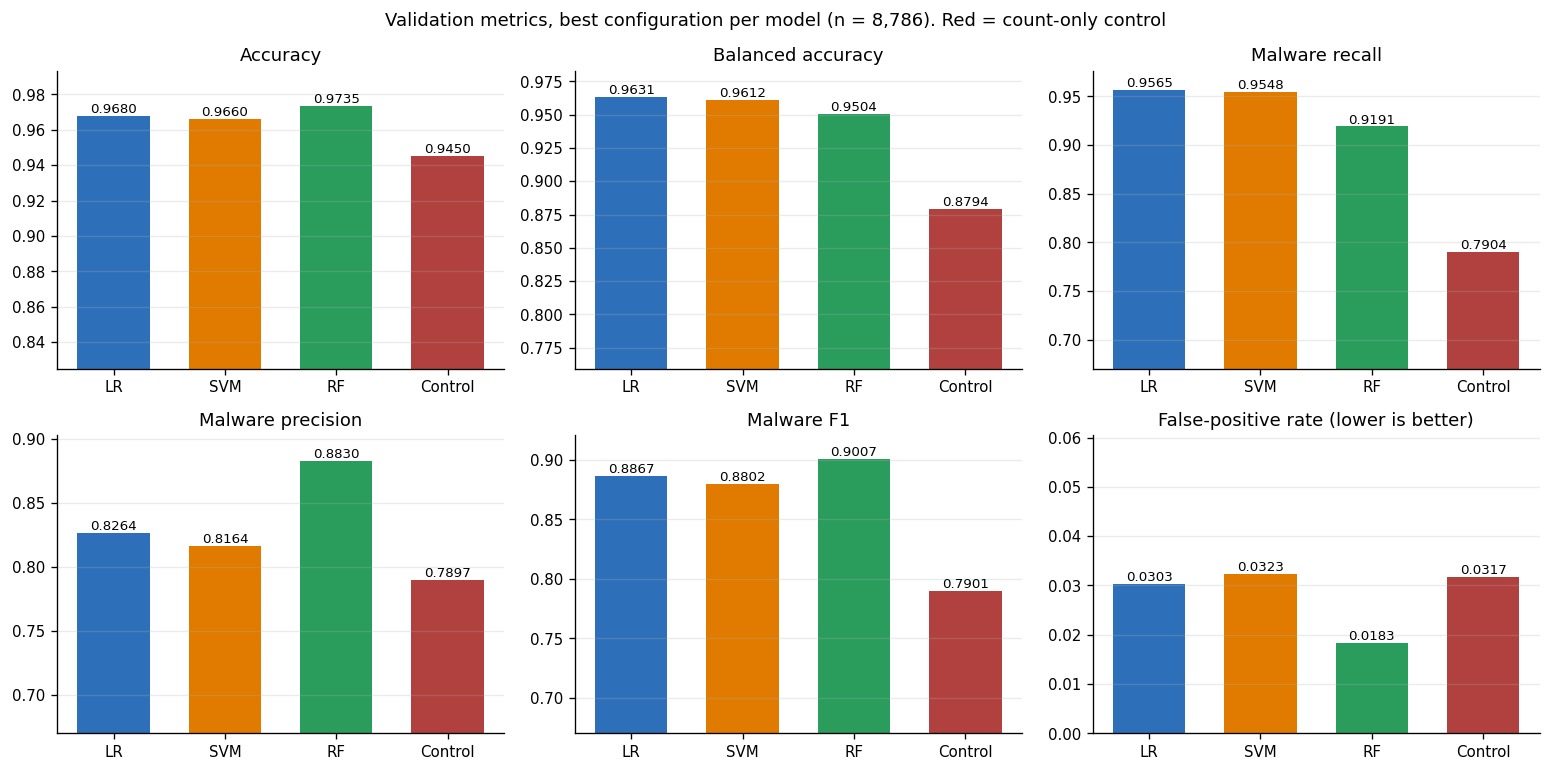

In [12]:
# Figure 4 - best configuration per model vs control (validation)
show = list(best_per_family.values) + ["CONTROL active-count"]
labels = ["LR", "SVM", "RF", "Control"]
order = [best_per_family[f] for f in ["Logistic Regression", "Linear SVM", "Random Forest"]] + ["CONTROL active-count"]
colors = [COL[val.loc[c, "family"]] for c in order]
mets = [("accuracy","Accuracy"), ("balanced_accuracy","Balanced accuracy"), ("malware_recall","Malware recall"),
        ("malware_precision","Malware precision"), ("malware_f1","Malware F1"), ("false_positive_rate","False-positive rate (lower is better)")]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (k, t) in zip(axes.ravel(), mets):
    v = [val.loc[c, k] for c in order]
    ax.bar(range(4), v, color=colors, width=.65); ax.set_xticks(range(4)); ax.set_xticklabels(labels)
    lo = 0 if k == "false_positive_rate" else max(0, min(v) - .12)
    ax.set_ylim(lo, max(v) * (1.25 if k == "false_positive_rate" else 1) + .02); ax.set_title(t)
    for i, x in enumerate(v): ax.text(i, x, f"{x:.4f}", ha="center", va="bottom", fontsize=8)
    ax.grid(axis="y", alpha=.25)
fig.suptitle(f"Validation metrics, best configuration per model (n = {len(y_va):,}). Red = count-only control")
fig.tight_layout(); plt.show()

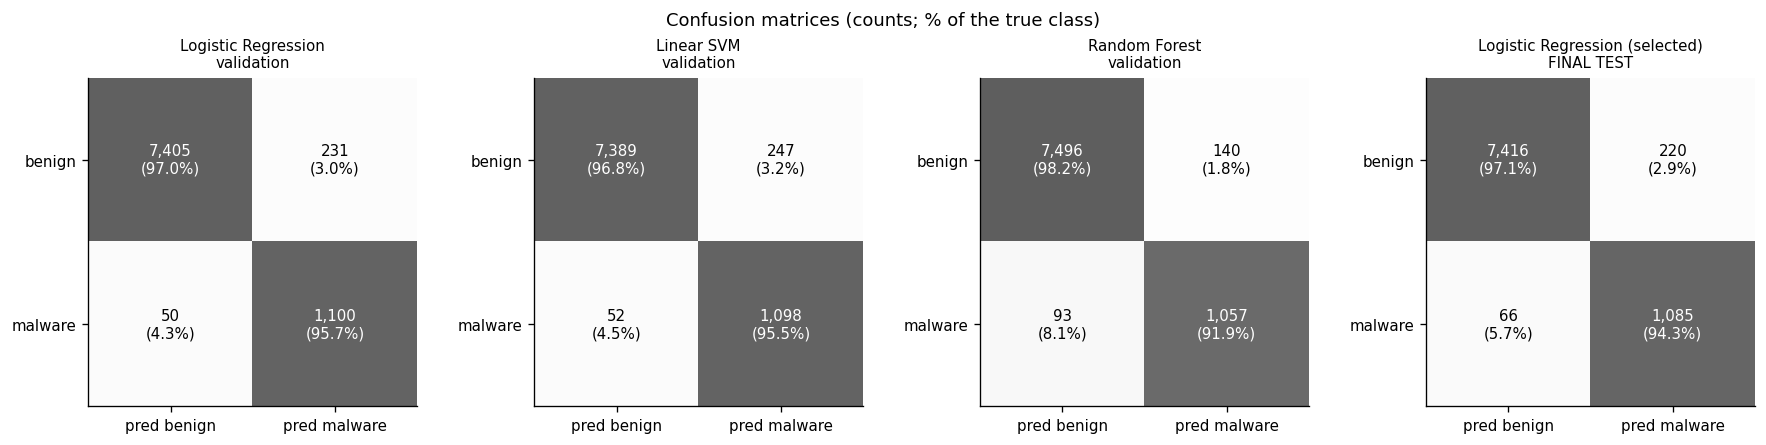

In [13]:
# Figure 5 - confusion matrices
panels = [(f"{val.loc[c,'family']}\nvalidation", val.loc[c, ["TN","FP","FN","TP"]].values) for c in order[:3]]
panels.append((f"{test['family']} (selected)\nFINAL TEST", np.array([test['TN'], test['FP'], test['FN'], test['TP']])))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (t, v) in zip(axes, panels):
    cm = np.array(v, dtype=int).reshape(2, 2); norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap="Greys", vmin=0, vmax=1.4)
    for (i, j), n in np.ndenumerate(cm):
        ax.text(j, i, f"{n:,}\n({norm[i,j]*100:.1f}%)", ha="center", va="center", color="white" if norm[i,j] > .7 else "black")
    ax.set_xticks([0,1]); ax.set_xticklabels(["pred benign","pred malware"])
    ax.set_yticks([0,1]); ax.set_yticklabels(["benign","malware"]); ax.set_title(t, fontsize=9)
fig.suptitle("Confusion matrices (counts; % of the true class)"); fig.tight_layout(); plt.show()

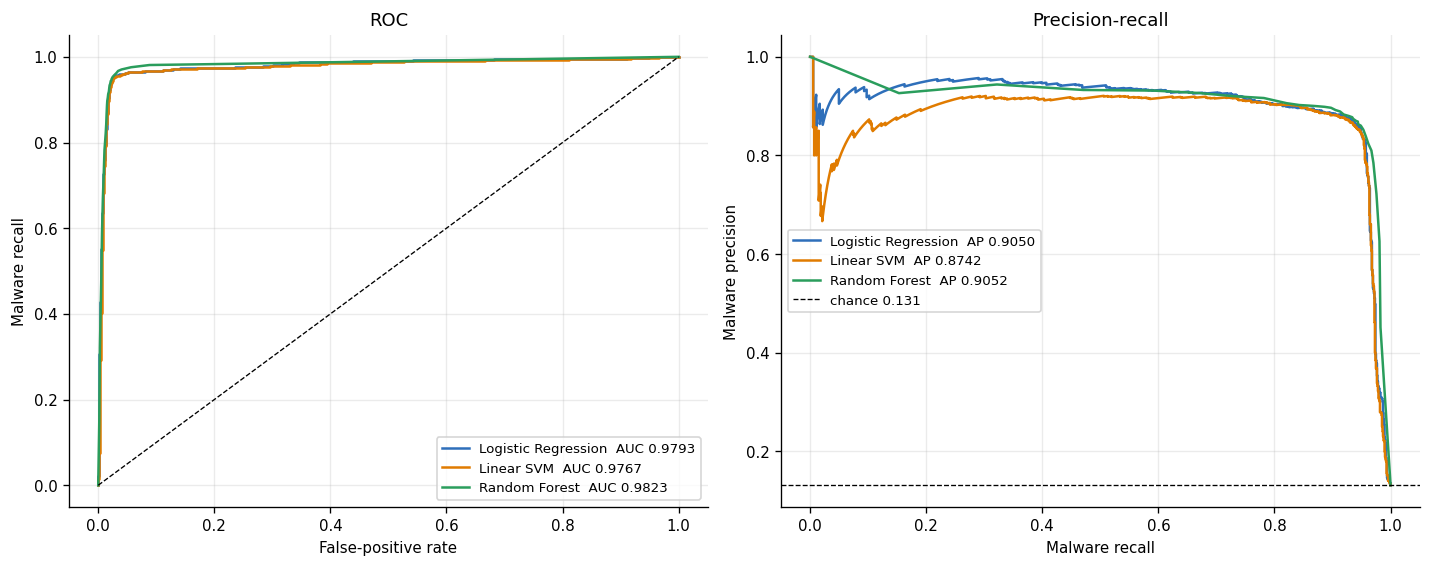

In [14]:
# Figure 6 - ROC and precision-recall (validation)
from sklearn.metrics import roc_curve, precision_recall_curve
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8))
for c in order[:3]:
    fam = val.loc[c, "family"]; s = val_scores[c]
    f, t, _ = roc_curve(y_va, s); p, r, _ = precision_recall_curve(y_va, s)
    a1.plot(f, t, color=COL[fam], label=f"{fam}  AUC {val.loc[c,'roc_auc']:.4f}")
    a2.plot(r, p, color=COL[fam], label=f"{fam}  AP {val.loc[c,'pr_auc']:.4f}")
a1.plot([0,1], [0,1], "k--", lw=.8); a2.axhline(y_va.mean(), color="k", ls="--", lw=.8, label=f"chance {y_va.mean():.3f}")
a1.set_xlabel("False-positive rate"); a1.set_ylabel("Malware recall"); a1.set_title("ROC")
a2.set_xlabel("Malware recall"); a2.set_ylabel("Malware precision"); a2.set_title("Precision-recall")
for a in (a1, a2): a.legend(fontsize=8); a.grid(alpha=.25)
fig.tight_layout(); plt.show()

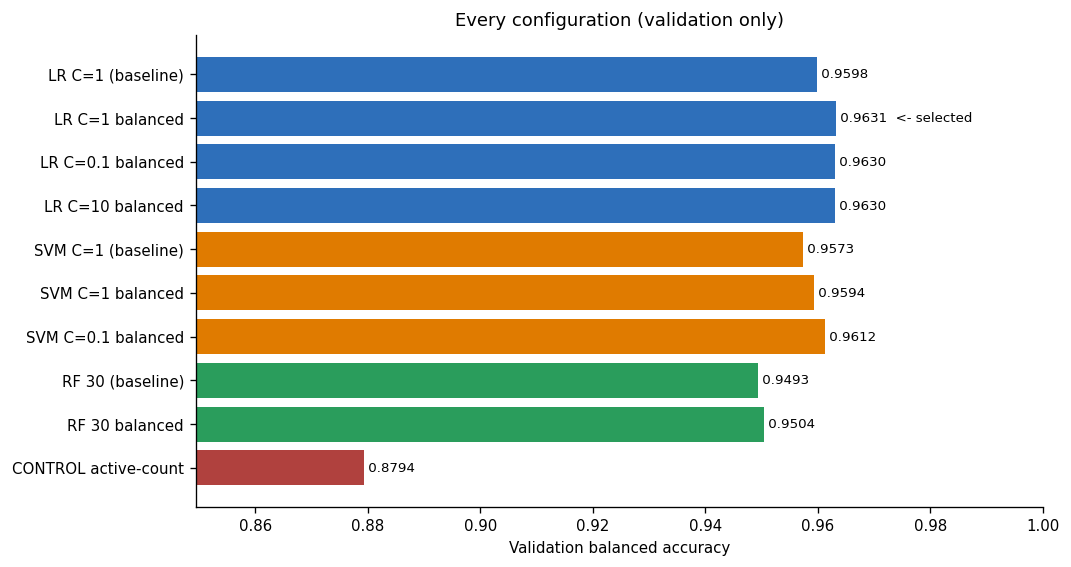

In [15]:
# Figure 8 - every configuration tried
fig, ax = plt.subplots(figsize=(9, 4.8))
yy = np.arange(len(val))
ax.barh(yy, val["balanced_accuracy"], color=[COL[f] for f in val["family"]])
ax.set_yticks(yy); ax.set_yticklabels([" ".join(c.split()) for c in val.index])
for i, (c, b) in enumerate(val["balanced_accuracy"].items()):
    ax.text(b, i, f" {b:.4f}" + ("  <- selected" if c == SELECTED else ""), va="center", fontsize=8)
ax.set_xlim(val["balanced_accuracy"].min() - .03, 1); ax.invert_yaxis()
ax.set_xlabel("Validation balanced accuracy"); ax.set_title("Every configuration (validation only)")
fig.tight_layout(); plt.show()

## 9. Does this run match the shipped project?

The values below are copied from `reports/results/model_evaluation.json`,
produced by `scripts/tune_models.py` with scikit-learn
1.6.1, NumPy 1.26.4, SciPy
1.15.3. Same versions → identical. Other versions → small
differences in the last digits are normal; large ones mean something differs
in the data or code.

In [16]:
SHIPPED_VALIDATION = {
    "LR  C=1    (baseline)": 0.9598,
    "LR  C=1    balanced": 0.9631,
    "LR  C=0.1  balanced": 0.963,
    "LR  C=10   balanced": 0.963,
    "SVM C=1    (baseline)": 0.9573,
    "SVM C=1    balanced": 0.9594,
    "SVM C=0.1  balanced": 0.9612,
    "RF  30     (baseline)": 0.9493,
    "RF  30     balanced": 0.9504,
    "CONTROL active-count": 0.8794
}
SHIPPED_SELECTED = "LR  C=1    balanced"
SHIPPED_TEST = {
    "accuracy": 0.9675,
    "balanced_accuracy": 0.9569,
    "malware_recall": 0.9427,
    "malware_precision": 0.8314,
    "roc_auc": 0.9785
}

print(f"scikit-learn here: {sklearn.__version__}   shipped: 1.6.1\n")
worst = 0
for cfg, ref in SHIPPED_VALIDATION.items():
    got = val.loc[cfg, "balanced_accuracy"]; worst = max(worst, abs(got - ref))
    print(f"  {cfg:24s} here {got:.4f}   shipped {ref:.4f}   diff {got-ref:+.4f}")
print(f"\nselected here: {SELECTED}   shipped: {SHIPPED_SELECTED}")
for k, ref in SHIPPED_TEST.items():
    print(f"  test {k:18s} here {test[k]:.4f}   shipped {ref:.4f}")
print("\nMATCH" if worst < 0.0005 else f"\nLargest validation difference: {worst:.4f}")

scikit-learn here: 1.6.1   shipped: 1.6.1

  LR  C=1    (baseline)    here 0.9598   shipped 0.9598   diff +0.0000
  LR  C=1    balanced      here 0.9631   shipped 0.9631   diff +0.0000
  LR  C=0.1  balanced      here 0.9630   shipped 0.9630   diff +0.0000
  LR  C=10   balanced      here 0.9630   shipped 0.9630   diff -0.0000
  SVM C=1    (baseline)    here 0.9573   shipped 0.9573   diff -0.0000
  SVM C=1    balanced      here 0.9594   shipped 0.9594   diff -0.0000
  SVM C=0.1  balanced      here 0.9612   shipped 0.9612   diff +0.0000
  RF  30     (baseline)    here 0.9493   shipped 0.9493   diff +0.0000
  RF  30     balanced      here 0.9504   shipped 0.9504   diff -0.0000
  CONTROL active-count     here 0.8794   shipped 0.8794   diff -0.0000

selected here: LR  C=1    balanced   shipped: LR  C=1    balanced
  test accuracy           here 0.9675   shipped 0.9675
  test balanced_accuracy  here 0.9569   shipped 0.9569
  test malware_recall     here 0.9427   shipped 0.9427
  test malware_

## 10. Reading the results

- **Quote balanced accuracy and malware recall, not accuracy alone.** Predicting
  "benign" for everything scores ~0.87 accuracy here.
- **The control matters.** A one-number model (how many features an app uses)
  already gets high accuracy, because malware in MH-100K uses far fewer
  features (median ~42 vs ~2,082). The real test is how far each model clears
  that control, above all in malware recall.
- **Random Forest** has the best accuracy and precision; **Logistic Regression**
  catches the most malware. The selection rule (balanced accuracy) was fixed
  before looking at results.
- Single split, no confidence intervals, no probability calibration.